In [32]:
import torch
import torchvision
import matplotlib.pyplot
import numpy
from torch.optim import Adam
#from torch.autograd import Variable
from torchvision.datasets import MNIST
from torchvision.transforms import transforms
from torch.utils.data import DataLoader

In [33]:
transformf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

batch_size = 10

In [34]:
Labels_number = 10
tags = ('0', '1', '2', '3', '4', '5', '6', '7', '8', '9')

In [35]:
from torchvision.datasets.mnist import MNIST
train_path = MNIST(root="./data",train=True,transform=transformf,download=True)
train_set = DataLoader(train_path,batch_size=batch_size, shuffle=True, num_workers=0)

In [36]:
test_path = MNIST(root="./data",train=False,transform=transformf,download=True)
test_set = DataLoader(test_path, batch_size=batch_size, shuffle=False, num_workers=0)

In [37]:
class Neural(torch.nn.Module):
    def __init__(self):
        super(Neural, self).__init__()
        
        self.conv1 = torch.nn.Conv2d(in_channels=1, out_channels=12, kernel_size=5, stride=1, padding=1)
        self.bn1 = torch.nn.BatchNorm2d(12)
        self.conv2 = torch.nn.Conv2d(in_channels=12, out_channels=12, kernel_size=5, stride=1, padding=1)
        self.bn2 = torch.nn.BatchNorm2d(12)
        self.pool = torch.nn.MaxPool2d(2,2)
        self.conv4 = torch.nn.Conv2d(in_channels=12, out_channels=24, kernel_size=5, stride=1, padding=1)
        self.bn4 = torch.nn.BatchNorm2d(24)
        self.conv5 = torch.nn.Conv2d(in_channels=24, out_channels=24, kernel_size=5, stride=1, padding=1)
        self.bn5 = torch.nn.BatchNorm2d(24)
        self.fc1 = torch.nn.Linear(24*8*8, 10)

    def forward(self, input):
        output = torch.nn.functional.relu(self.bn1(self.conv1(input)))      
        output = torch.nn.functional.relu(self.bn2(self.conv2(output)))     
        output = self.pool(output)                        
        output = torch.nn.functional.relu(self.bn4(self.conv4(output)))     
        output = torch.nn.functional.relu(self.bn5(self.conv5(output)))   
        output = output.view(-1, 24*8*8)
        output = self.fc1(output)

        return output

Neironka = Neural()

In [38]:
loss_fn = torch.nn.CrossEntropyLoss()
optimizer = Adam(Neironka.parameters(), lr=0.001, weight_decay=0.0001)

In [39]:
def train(num_epochs):
    
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    #print("The model will be running on", device, "device")
    Neironka.to(device)

    for epoch in range(num_epochs):
        running_loss = 0.0
        running_acc = 0.0

        for i, (images, labels) in enumerate(train_set, 0):
            
            images = Variable(images.to(device))
            labels = Variable(labels.to(device))

            optimizer.zero_grad()
            outputs = Neironka(images)
            loss = loss_fn(outputs, labels)
            loss.backward()
            optimizer.step()

        accuracy = testAccuracy()
        print('Эпоха', epoch+1,' закончилась с точностью ', accuracy)

In [40]:
def testAccuracy():
    
    Neironka.eval()
    accuracy = 0.0
    total = 0.0
    
    with torch.no_grad():
        for data in test_set:
            images, labels = data
            outputs = Neironka(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            accuracy += (predicted == labels).sum().item()

    accuracy = (accuracy / total)
    return(accuracy)

In [41]:
def showImages(img):
    img = img / 2 + 0.5
    npimg = img.numpy()
    matplotlib.pyplot.imshow(numpy.transpose(npimg, (1, 2, 0)))
    matplotlib.pyplot.show()

In [42]:
def finalTest():
    images, labels = next(iter(test_set))

    showImages(torchvision.utils.make_grid(images))
    print('Реальное значение: ', ' '.join('%5s' % tags[labels[j]] 
                               for j in range(batch_size)))
  
    outputs = Neironka(images)
    _, predicted = torch.max(outputs, 1)
    print('Предположительное: ', ' '.join('%5s' % tags[predicted[j]] 
                              for j in range(batch_size)))

In [44]:
train(1)
print('\n Модель закончила обучение')

Эпоха 1  закончилась с точностью  0.9861

 Модель закончила обучение


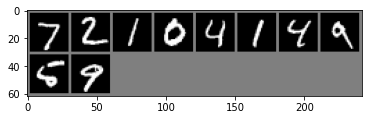

Реальное значение:      7     2     1     0     4     1     4     9     5     9
Предположительное:      7     2     1     0     4     1     4     9     5     9


In [31]:
finalTest()